# Figures 13–14 — performance vs hardness ($N=22$ NIKKEI 225 market graphs)

Standalone QAOA ($p=6$, 500 shots on the kernel) vs qReduMIS powered by QAOA ($p=6$, $\mathrm{qshots}=10$, 20 classical shots)
on $250$ instances: 10 seeds × 25 correlation thresholds $\lambda$. The hardness parameter of the (first) kernel is
$\mathbb{H} = D_{|\mathrm{MIS}|-1} / (|\mathrm{MIS}| \cdot D_{|\mathrm{MIS}|})$; $57$ instances have a non-empty kernel and $\mathbb{H}>0$.

- **Fig. 13** (`figures/final_hardness_vs_threshold_heatmap_N22.png`): kernel hardness vs threshold $\lambda$, coloured by kernel size $K$.
- **Fig. 14** (`figures/final_metrics_vs_hardness_N22.png`): $P_{\mathrm{MIS}}$, optTTS and $\langle|IS|\rangle/|\mathrm{MIS}|$ vs $\mathbb{H}$.

## Weighted energy (expected IS size from counts)

For each instance we compute the **expected independent-set size** weighted by measurement counts:

$$\langle |IS| \rangle = \frac{\sum_i |IS_i| \times c_i}{\sum_i c_i}$$

- **QAOA**: uses `clean_counts` (500 shots on the kernel) → normalised by kernel MIS (baseline)
- **qReduMIS**: uses `prefixup_counts` (10 shots per QPU call, pooled across all cshots & iterations) → normalised by full-graph MIS

In [1]:
%matplotlib inline
# --- location-independent repo-root finder (walks up to the folder that
#     contains both the qReduMIS/ package and pyproject.toml) ---
def _find_repo_root(_start=None):
    import os as _os
    _d = _os.path.abspath(_start or _os.getcwd())
    while _d != _os.path.dirname(_d):
        if _os.path.isfile(_os.path.join(_d, 'pyproject.toml')) and (
                _os.path.isdir(_os.path.join(_d, 'qReduMIS_package'))
                or _os.path.isdir(_os.path.join(_d, 'qReduMIS'))):
            return _d
        _d = _os.path.dirname(_d)
    raise RuntimeError('Could not locate qReduMIS repo root (need a parent dir with pyproject.toml and qReduMIS_package/)')

import sys, os, json, glob, sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
from collections import defaultdict

_REL_ROOT = os.getcwd() if os.path.isdir("consolidated_results") else os.path.abspath(os.pardir)  # release root (re-run safe)
sys.path.insert(0, _REL_ROOT)  # release root (for utils/)

sys.path.insert(0, _find_repo_root())  # project root

from utils.opt_tts_estimator import estimate_opt_tts
from utils.mis_degeneracy import analyze_graph, count_independent_sets
from utils.solver_baseline import or_tool_solver as maximum_independent_set
# --- NumPy 2.0 compatibility shim -------------------------------------------
# networkx 2.8.8 (the version pinned by qReduMIS) still references the legacy
# aliases np.float_/np.int_ in its GraphML type table, which NumPy >= 2.0
# removed.  Restore them *before* importing networkx so read_graphml works.
import numpy as _np_compat

for _legacy, _modern in (
    ("float_", "float64"),
    ("int_", "int64"),
    ("complex_", "complex128"),
    ("unicode_", "str_"),
):
    if not hasattr(_np_compat, _legacy):
        setattr(_np_compat, _legacy, getattr(_np_compat, _modern))
# ----------------------------------------------------------------------------
import networkx as nx

matplotlib.rcParams.update({
    'font.size': 14, 'axes.titlesize': 16, 'axes.labelsize': 14,
    'xtick.labelsize': 14, 'ytick.labelsize': 14,
    'legend.fontsize': 12, 'figure.dpi': 120,
})

colors = {"QAOA": "blue", "qReduMIS": "green"}
markers = {"QAOA": "o", "qReduMIS": "s"}

print("Imports OK")

Imports OK


In [2]:
# ── Paths ──────────────────────────────────────────────────────────────
BASE = _REL_ROOT
os.chdir(BASE)  # resolve relative paths from the release root

SAVE_FIGURES = False  # set False to skip saving figures
os.makedirs("figures", exist_ok=True)

# Original 10 thresholds
INSTANCES_DIR_1 = os.path.join(BASE, "problem_instances/density_sweep_N22")
RESULTS_ROOT_1  = os.path.join(BASE, "data/data_portfolio_selection/results_emu_densities_N22", "results_emu_densities_N22")

# New 15 thresholds
INSTANCES_DIR_2 = os.path.join(BASE, "problem_instances/density_sweep_N22_extra")
RESULTS_ROOT_2  = os.path.join(BASE, "data/data_portfolio_selection/results_emu_densities_N22_more", "results_emu_densities_N22_more")

# Combine both instance sets
INSTANCES_DIRS = [INSTANCES_DIR_1, INSTANCES_DIR_2]
RESULTS_ROOTS  = [RESULTS_ROOT_1, RESULTS_ROOT_2]

# Keep backward-compat aliases
INSTANCES_DIR = INSTANCES_DIR_1
RESULTS_ROOT  = RESULTS_ROOT_1

# Load and merge generation summaries
gen_summary = []
for inst_dir in INSTANCES_DIRS:
    summary_path = os.path.join(inst_dir, "generation_summary.json")
    if os.path.exists(summary_path):
        with open(summary_path) as f:
            data = json.load(f)
        # Tag each entry with its instances directory
        for d in data:
            d["_instances_dir"] = inst_dir
        gen_summary.extend(data)
        print(f"  Loaded {len(data)} instances from {os.path.basename(inst_dir)}")

# Build lookup: (threshold, seed) -> {kernel_size, n_edges, ...}
instance_info = {}
for d in gen_summary:
    instance_info[(d["threshold"], d["seed"])] = d

thresholds = sorted(set(d["threshold"] for d in gen_summary))
N = 22

print(f"\nTotal: {len(gen_summary)} instances across {len(thresholds)} thresholds")
print(f"Thresholds: {thresholds}")
print(f"Results roots: {[os.path.relpath(r, BASE) for r in RESULTS_ROOTS]}")

  Loaded 100 instances from density_sweep_N22
  Loaded 150 instances from density_sweep_N22_extra

Total: 250 instances across 25 thresholds
Thresholds: [0.001, 0.112, 0.223, 0.25, 0.275, 0.3, 0.32, 0.334, 0.35, 0.37, 0.39, 0.41, 0.43, 0.445, 0.46, 0.48, 0.5, 0.52, 0.54, 0.556, 0.56, 0.667, 0.778, 0.889, 1.0]
Results roots: ['data/data_portfolio_selection/results_emu_densities_N22/results_emu_densities_N22', 'data/data_portfolio_selection/results_emu_densities_N22_more/results_emu_densities_N22_more']


## 1. Compute Ground Truth (MIS) for Each Instance

In [3]:
# Compute ground truth MIS for every (threshold, seed) instance
# using the FULL graph (not the kernel)
gt = {}   # (threshold, seed) -> mis_size
gt_flat = {}  # (N, seed, threshold) -> mis_size — for later

for d in gen_summary:
    thres = d["threshold"]
    seed = d["seed"]
    inst_dir = d.get("_instances_dir", INSTANCES_DIR)
    graph_path = os.path.join(
        inst_dir,
        f"graph_unweighted_N{N}_seed{seed}_thres{thres}.graphml"
    )
    G = nx.read_graphml(graph_path)
    sol = maximum_independent_set(G)
    mis_size = len(sol)
    gt[(thres, seed)] = mis_size
    gt_flat[(N, seed, thres)] = mis_size

print(f"Computed ground truth for {len(gt)} instances")
# Show a summary per threshold
for thres in thresholds:
    seeds_for_thres = sorted([s for (t, s) in gt if t == thres])
    sizes = [gt[(thres, s)] for s in seeds_for_thres]
    print(f"  thres={thres:.3f}: MIS sizes = {sizes}")

Computed ground truth for 250 instances
  thres=0.001: MIS sizes = [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
  thres=0.112: MIS sizes = [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
  thres=0.223: MIS sizes = [1, 1, 2, 1, 1, 2, 1, 2, 2, 2]
  thres=0.250: MIS sizes = [1, 1, 2, 2, 2, 2, 1, 2, 2, 2]
  thres=0.275: MIS sizes = [1, 1, 2, 2, 2, 2, 1, 2, 2, 2]
  thres=0.300: MIS sizes = [2, 1, 2, 2, 2, 2, 1, 2, 2, 3]
  thres=0.320: MIS sizes = [2, 1, 2, 2, 2, 3, 1, 2, 3, 3]
  thres=0.334: MIS sizes = [2, 1, 3, 3, 2, 3, 2, 2, 3, 3]
  thres=0.350: MIS sizes = [2, 1, 3, 3, 2, 3, 2, 2, 3, 3]
  thres=0.370: MIS sizes = [3, 2, 3, 3, 3, 3, 2, 3, 3, 4]
  thres=0.390: MIS sizes = [3, 2, 3, 3, 3, 3, 3, 3, 3, 5]
  thres=0.410: MIS sizes = [4, 3, 3, 3, 3, 5, 3, 3, 5, 5]
  thres=0.430: MIS sizes = [4, 3, 3, 4, 4, 6, 3, 3, 5, 7]
  thres=0.445: MIS sizes = [5, 3, 3, 4, 4, 7, 4, 4, 7, 8]
  thres=0.460: MIS sizes = [5, 4, 5, 5, 4, 7, 4, 5, 7, 9]
  thres=0.480: MIS sizes = [6, 5, 6, 5, 5, 8, 5, 6, 7, 11]
  thres=0.500: MIS sizes = [7, 

## 2. Load Results from SQLite DBs

In [4]:
from utils.derived import DerivedData

D = DerivedData()   # consolidated tables under consolidated_results/


def load_qaoa_results(db_path):
    """Load QAOA results -> list of dicts with N, seed, p, mis, pmis, baseline."""
    return D.db_records(db_path)


def load_qredumis_results(db_path):
    """Load qReduMIS results -> list of dicts with N, seed, cshot, p, atom positions MIS."""
    return D.db_records(db_path)


# ── Collect all results per threshold (from ALL results roots) ─────────
all_qaoa = []     # list of dicts: {threshold, seed, ...}
all_qredumis = [] # list of dicts: {threshold, seed, cshot, ...}

# Track which result directory was selected per threshold (for weighted energy)
qaoa_result_dir = {}   # threshold -> dir path
qr_result_dir = {}     # threshold -> dir path

for results_root in RESULTS_ROOTS:
    if not D.known_dirs(os.path.join(results_root, "thres_*", "*")):
        print(f"  WARN: no recorded results under: {results_root}")
        continue

    for thres in thresholds:
        thres_dir = os.path.join(results_root, f"thres_{thres}")

        # Skip if already loaded from a previous root
        if thres not in qaoa_result_dir:
            # QAOA: prefer latest date
            qaoa_dirs = D.known_dirs(os.path.join(thres_dir, "qaoa_p6_*"))
            for qd in reversed(qaoa_dirs):  # latest first
                db = os.path.join(qd, "benchmark_qaoa.db")
                results = load_qaoa_results(db)
                if results:
                    for r in results:
                        r["threshold"] = thres
                    all_qaoa.extend(results)
                    qaoa_result_dir[thres] = qd
                    break

        if thres not in qr_result_dir:
            # qReduMIS: prefer latest date
            qr_dirs = D.known_dirs(os.path.join(thres_dir, "qredumis_p6_*"))
            for qd in reversed(qr_dirs):
                db = os.path.join(qd, "benchmark_qredumis.db")
                results = load_qredumis_results(db)
                if results:
                    for r in results:
                        r["threshold"] = thres
                    all_qredumis.extend(results)
                    qr_result_dir[thres] = qd
                    break

print(f"Loaded {len(all_qaoa)} QAOA rows, {len(all_qredumis)} qReduMIS rows")
print(f"QAOA result dirs: {len(qaoa_result_dir)} thresholds, qReduMIS result dirs: {len(qr_result_dir)} thresholds")
print(f"Thresholds with QAOA results: {sorted(qaoa_result_dir.keys())}")
print(f"Thresholds with qReduMIS results: {sorted(qr_result_dir.keys())}")

Loaded 230 QAOA rows, 4979 qReduMIS rows
QAOA result dirs: 25 thresholds, qReduMIS result dirs: 25 thresholds
Thresholds with QAOA results: [0.001, 0.112, 0.223, 0.25, 0.275, 0.3, 0.32, 0.334, 0.35, 0.37, 0.39, 0.41, 0.43, 0.445, 0.46, 0.48, 0.5, 0.52, 0.54, 0.556, 0.56, 0.667, 0.778, 0.889, 1.0]
Thresholds with qReduMIS results: [0.001, 0.112, 0.223, 0.25, 0.275, 0.3, 0.32, 0.334, 0.35, 0.37, 0.39, 0.41, 0.43, 0.445, 0.46, 0.48, 0.5, 0.52, 0.54, 0.556, 0.56, 0.667, 0.778, 0.889, 1.0]


In [5]:
# ══════════════════════════════════════════════════════════════════════════════
# 2b. Compute Weighted Energy (expected IS size from counts)
#     + per-instance bootstrap std over the raw shots / cshots
#
#   QAOA:     ⟨|IS|⟩ = Σ(|IS_i| × count_i) / Σ(count_i)  from clean_counts
#             weighted_ar = ⟨|IS|⟩ / baseline  (kernel MIS)
#             Bootstrap: resample the 500 individual shots with replacement
#
#   qReduMIS: ⟨|IS|⟩ = mean(|W_i|) across cshots  from intermediate_iterations
#             weighted_ar = ⟨|IS|⟩ / gt_mis  (full-graph MIS)
#             Bootstrap: resample the 20 cshots with replacement
# ══════════════════════════════════════════════════════════════════════════════
import re

from utils.derived import DerivedData

D = DerivedData()   # consolidated tables under derived/

N_BOOT = 1000
_boot_rng = np.random.default_rng(42)

# ── QAOA weighted energy per (threshold, seed) ──────────────────────────
we_qaoa_lookup = {}      # (threshold, seed) -> weighted_ar
we_qaoa_std_lookup = {}  # (threshold, seed) -> bootstrap std

for thres, qd in qaoa_result_dir.items():
    counts_dir = os.path.join(qd, "counts")
    instances = D.counts_instances(counts_dir)
    if not instances:
        continue

    # Get baselines from consolidated_results/benchmarks.csv
    db = os.path.join(qd, "benchmark_qaoa.db")
    baselines = {}
    for d in D.db_records(db):
        baselines[(d["N"], d["seed"])] = d["baseline"]

    # Walk the consolidated counts in the same order as the
    # clean_counts_*.json files they replace
    for n_val, seed, p_val in instances:
        cc = D.counts_records(counts_dir, n_val, seed, p_val)
        total_shots = sum(e["count"] for e in cc)
        if total_shots == 0:
            continue
        bl = baselines.get((n_val, seed))
        if bl is None or bl == 0:
            continue

        # Expand to individual IS sizes (one per shot)
        is_sizes = np.array([len(e["nodes"]) for e in cc for _ in range(e["count"])])
        avg_is = np.mean(is_sizes)
        we_qaoa_lookup[(thres, seed)] = avg_is / bl

        # Bootstrap over the 500 shots
        boot_vals = np.array([
            np.mean(_boot_rng.choice(is_sizes, size=len(is_sizes), replace=True)) / bl
            for _ in range(N_BOOT)
        ])
        we_qaoa_std_lookup[(thres, seed)] = np.std(boot_vals)

print(f"QAOA weighted energy: {len(we_qaoa_lookup)} instances, "
      f"bootstrap std computed for {len(we_qaoa_std_lookup)}")


# ── qReduMIS weighted energy per (threshold, seed) ──────────────────────
we_qr_lookup = {}      # (threshold, seed) -> weighted_ar
we_qr_std_lookup = {}  # (threshold, seed) -> bootstrap std

for thres, qd in qr_result_dir.items():
    inter_dir = os.path.join(qd, "intermediate_iterations")

    # seed -> [final |W| per cshot], from consolidated_results/iterations.csv.
    # (The table already marks the highest iteration per (N, seed, cshot),
    # which is what the raw-file version recovered by scanning filenames.)
    w_sizes = D.W_sizes_by_seed(inter_dir)
    if not w_sizes:
        continue

    for seed, sizes in sorted(w_sizes.items()):
        gt_mis = gt.get((thres, seed), 0)
        if gt_mis == 0:
            continue
        sizes_arr = np.array(sizes)
        avg_is = np.mean(sizes_arr)
        we_qr_lookup[(thres, seed)] = avg_is / gt_mis

        # Bootstrap over the 20 cshots
        boot_vals = np.array([
            np.mean(_boot_rng.choice(sizes_arr, size=len(sizes_arr), replace=True)) / gt_mis
            for _ in range(N_BOOT)
        ])
        we_qr_std_lookup[(thres, seed)] = np.std(boot_vals)

print(f"qReduMIS weighted energy: {len(we_qr_lookup)} instances, "
      f"bootstrap std computed for {len(we_qr_std_lookup)}")

QAOA weighted energy: 57 instances, bootstrap std computed for 57


qReduMIS weighted energy: 250 instances, bootstrap std computed for 250


## 3. Compute Metrics

In [6]:
# ══════════════════════════════════════════════════════════════════════════════
# 3a. QAOA metrics per (threshold, seed)
# ══════════════════════════════════════════════════════════════════════════════
QAOA_TOTAL_SHOTS = 500  # total shots per QAOA instance
N_BOOT_TTS = 1_000       # bootstrap resamples for optTTS CI

qaoa_records = []
rng_boot_qaoa = np.random.default_rng(42)

for r in all_qaoa:
    thres = r["threshold"]
    seed = r["seed"]
    baseline = r["baseline"]
    mis_found = r["mis"]
    pmis = r["pmis"]
    info = instance_info.get((thres, seed), {})
    n_edges = info.get("n_edges", 0)
    kernel_size = info.get("kernel_size", 0)
    density = 2 * n_edges / (N * (N - 1)) if N > 1 else 0

    # Weighted energy (expected IS size / MIS) from clean_counts
    w_ar = we_qaoa_lookup.get((thres, seed), np.nan)
    w_ar_std = we_qaoa_std_lookup.get((thres, seed), np.nan)
    if kernel_size == 0:
        w_ar = 1.0
        w_ar_std = 0.0

    # Success probability (from DB: pmis)
    p_success = pmis
    p_success_std = np.sqrt(p_success * (1 - p_success) / QAOA_TOTAL_SHOTS) if 0 < p_success < 1 else 0.0

    # optTTS: TTS = cost * ln(1-p_d) / ln(1-p_s)
    p_d = 0.99
    cost_per_call = 1.0  # QAOA: 1 shot = 1 unit cost
    if kernel_size == 0:
        opt_tts = 0.0
        opt_tts_lo, opt_tts_hi = 0.0, 0.0
    elif p_success > 0 and p_success < 1:
        opt_tts = cost_per_call * np.log(1 - p_d) / np.log(1 - p_success)
        # Bootstrap CI (binomial resampling, same as opt_tts_estimator)
        n_success_obs = int(round(p_success * QAOA_TOTAL_SHOTS))
        boot_gs = rng_boot_qaoa.binomial(QAOA_TOTAL_SHOTS, p_success, size=N_BOOT_TTS)
        boot_ps = (boot_gs - 0.5) / QAOA_TOTAL_SHOTS
        boot_ps = np.clip(boot_ps, 1e-10, 1.0 - 1e-10)
        boot_tts = cost_per_call * np.log(1 - p_d) / np.log(1 - boot_ps)
        boot_tts[boot_gs == 0] = np.inf
        opt_tts_lo = float(np.percentile(boot_tts[np.isfinite(boot_tts)], 2.5)) if np.any(np.isfinite(boot_tts)) else np.inf
        opt_tts_hi = float(np.percentile(boot_tts[np.isfinite(boot_tts)], 97.5)) if np.any(np.isfinite(boot_tts)) else np.inf
    elif p_success >= 1.0:
        opt_tts = cost_per_call
        opt_tts_lo, opt_tts_hi = cost_per_call, cost_per_call
    else:
        opt_tts = np.inf
        opt_tts_lo, opt_tts_hi = np.inf, np.inf

    qaoa_records.append({
        "threshold": thres, "seed": seed,
        "n_edges": n_edges, "density": density,
        "kernel_size": kernel_size,
        "gt_mis": baseline, "mis_found": mis_found,
        "p_success": p_success, "p_success_std": p_success_std,
        "weighted_ar": w_ar, "weighted_ar_std": w_ar_std,
        "opt_tts": opt_tts, "opt_tts_lo": opt_tts_lo, "opt_tts_hi": opt_tts_hi,
        "method": "QAOA",
    })

df_qaoa = pd.DataFrame(qaoa_records)

print(f"QAOA: {len(df_qaoa)} instances")
print(f"  weighted_ar coverage: {df_qaoa['weighted_ar'].notna().sum()}/{len(df_qaoa)}")
print(f"  mean weighted_ar: {df_qaoa['weighted_ar'].mean():.4f}")
print(f"  mean weighted_ar_std: {df_qaoa['weighted_ar_std'].mean():.4f}")
# Show optTTS CI for nontrivial instances
nt_qaoa = df_qaoa[df_qaoa["kernel_size"] > 0]
finite_nt = nt_qaoa[np.isfinite(nt_qaoa["opt_tts"])]
print(f"  optTTS CI (nontrivial, finite): {len(finite_nt)} instances")
if len(finite_nt) > 0:
    print(f"    opt_tts range: [{finite_nt['opt_tts'].min():.1f}, {finite_nt['opt_tts'].max():.1f}]")
    print(f"    CI widths: [{(finite_nt['opt_tts_hi'] - finite_nt['opt_tts_lo']).min():.1f}, {(finite_nt['opt_tts_hi'] - finite_nt['opt_tts_lo']).max():.1f}]")

QAOA: 230 instances
  weighted_ar coverage: 230/230
  mean weighted_ar: 0.9579
  mean weighted_ar_std: 0.0019
  optTTS CI (nontrivial, finite): 57 instances
    opt_tts range: [1.0, 93.6]
    CI widths: [0.0, 88.0]


In [7]:
# ══════════════════════════════════════════════════════════════════════════════
# 3b. qReduMIS metrics per (threshold, seed)
#     - Success prob = fraction of cshots whose |IS| == gt_mis
#     - Weighted AR = mean(|W|)/gt_mis from intermediate_iterations
#     - optTTS = cost * ln(1-p_d) / ln(1-p_success) where cost = 10 * mean_iterations
# ══════════════════════════════════════════════════════════════════════════════

# Group cshots by (threshold, seed)
qr_by_instance = defaultdict(list)
for r in all_qredumis:
    key = (r["threshold"], r["seed"])
    mis_size = len(r["atom positions MIS"])
    n_iter = r.get("num iteration", 1)
    qr_by_instance[key].append({"mis_size": mis_size, "n_iter": n_iter})

qr_records = []
p_d = 0.99
QSHOTS_QREDUMIS = 10  # quantum shots per qReduMIS QPU call
rng_boot_qr = np.random.default_rng(43)

for (thres, seed), cshots in qr_by_instance.items():
    gt_mis = gt.get((thres, seed), 0)
    info = instance_info.get((thres, seed), {})
    n_edges = info.get("n_edges", 0)
    kernel_size = info.get("kernel_size", 0)
    density = 2 * n_edges / (N * (N - 1)) if N > 1 else 0

    sizes = [c["mis_size"] for c in cshots]
    iters = [c["n_iter"] for c in cshots]
    n_cshots = len(cshots)

    best_mis = max(sizes)
    n_success = sum(1 for s in sizes if s == gt_mis) if gt_mis > 0 else n_cshots
    p_success = n_success / n_cshots
    p_success_std = np.sqrt(p_success * (1 - p_success) / n_cshots) if 0 < p_success < 1 else 0.0

    # Weighted energy from intermediate_iterations (mean |W| / MIS)
    w_ar = we_qr_lookup.get((thres, seed), np.nan)
    w_ar_std = we_qr_std_lookup.get((thres, seed), np.nan)
    if kernel_size == 0:
        w_ar = 1.0
        w_ar_std = 0.0

    # Cost per trial = qshots * mean iterations
    mean_iter = np.mean(iters)
    cost = QSHOTS_QREDUMIS * mean_iter

    if kernel_size == 0:
        opt_tts = 0.0
        opt_tts_lo, opt_tts_hi = 0.0, 0.0
    elif p_success > 0 and p_success < 1:
        opt_tts = cost * np.log(1 - p_d) / np.log(1 - p_success)
        # Bootstrap CI (binomial resampling, same as opt_tts_estimator)
        boot_gs = rng_boot_qr.binomial(n_cshots, p_success, size=N_BOOT_TTS)
        boot_ps = (boot_gs - 0.5) / n_cshots
        boot_ps = np.clip(boot_ps, 1e-10, 1.0 - 1e-10)
        boot_tts = cost * np.log(1 - p_d) / np.log(1 - boot_ps)
        boot_tts[boot_gs == 0] = np.inf
        opt_tts_lo = float(np.percentile(boot_tts[np.isfinite(boot_tts)], 2.5)) if np.any(np.isfinite(boot_tts)) else np.inf
        opt_tts_hi = float(np.percentile(boot_tts[np.isfinite(boot_tts)], 97.5)) if np.any(np.isfinite(boot_tts)) else np.inf
    elif p_success >= 1.0:
        opt_tts = cost
        opt_tts_lo, opt_tts_hi = cost, cost
    else:
        opt_tts = np.inf
        opt_tts_lo, opt_tts_hi = np.inf, np.inf

    qr_records.append({
        "threshold": thres, "seed": seed,
        "n_edges": n_edges, "density": density,
        "kernel_size": kernel_size,
        "gt_mis": gt_mis, "mis_found": best_mis,
        "p_success": p_success, "p_success_std": p_success_std,
        "weighted_ar": w_ar, "weighted_ar_std": w_ar_std,
        "opt_tts": opt_tts, "opt_tts_lo": opt_tts_lo, "opt_tts_hi": opt_tts_hi,
        "n_cshots": n_cshots, "mean_iterations": mean_iter,
        "method": "qReduMIS",
    })

df_qr = pd.DataFrame(qr_records)

print(f"qReduMIS: {len(df_qr)} instances")
print(f"  weighted_ar coverage: {df_qr['weighted_ar'].notna().sum()}/{len(df_qr)}")
print(f"  mean weighted_ar: {df_qr['weighted_ar'].mean():.4f}")
print(f"  mean weighted_ar_std: {df_qr['weighted_ar_std'].mean():.4f}")
# Show optTTS CI for nontrivial instances
nt_qr = df_qr[df_qr["kernel_size"] > 0]
finite_nt_qr = nt_qr[np.isfinite(nt_qr["opt_tts"])]
print(f"  optTTS CI (nontrivial, finite): {len(finite_nt_qr)} instances")
if len(finite_nt_qr) > 0:
    print(f"    opt_tts range: [{finite_nt_qr['opt_tts'].min():.1f}, {finite_nt_qr['opt_tts'].max():.1f}]")
    print(f"    CI widths: [{(finite_nt_qr['opt_tts_hi'] - finite_nt_qr['opt_tts_lo']).min():.1f}, {(finite_nt_qr['opt_tts_hi'] - finite_nt_qr['opt_tts_lo']).max():.1f}]")
df_qr.head()

qReduMIS: 250 instances
  weighted_ar coverage: 250/250
  mean weighted_ar: 0.9987
  mean weighted_ar_std: 0.0007
  optTTS CI (nontrivial, finite): 57 instances
    opt_tts range: [10.0, 57.7]
    CI widths: [0.0, 112.3]


,threshold,seed,n_edges,density,kernel_size,gt_mis,mis_found,p_success,p_success_std,weighted_ar,weighted_ar_std,opt_tts,opt_tts_lo,opt_tts_hi,n_cshots,mean_iterations,method
0,0.001,0,231,1.0,0,1,1,1.0,0.0,1.0,0.0,0.0,0.0,0.0,18,0.0,qReduMIS
1,0.001,1,231,1.0,0,1,1,1.0,0.0,1.0,0.0,0.0,0.0,0.0,20,0.0,qReduMIS
2,0.001,2,231,1.0,0,1,1,1.0,0.0,1.0,0.0,0.0,0.0,0.0,20,0.0,qReduMIS
3,0.001,3,231,1.0,0,1,1,1.0,0.0,1.0,0.0,0.0,0.0,0.0,20,0.0,qReduMIS
4,0.001,4,231,1.0,0,1,1,1.0,0.0,1.0,0.0,0.0,0.0,0.0,20,0.0,qReduMIS


In [8]:
# ── Merge into a single DataFrame ────────────────────────────────────
df_all = pd.concat([df_qaoa, df_qr], ignore_index=True)
print(f"Combined: {len(df_all)} rows ({df_all['method'].value_counts().to_dict()})")

# Also create a wide-format merge on (threshold, seed) for paired comparison
df_wide = df_qaoa.merge(
    df_qr, on=["threshold", "seed"], suffixes=("_qaoa", "_qr"),
    how="inner"
)
print(f"Paired instances (both methods): {len(df_wide)}")

Combined: 480 rows ({'qReduMIS': 250, 'QAOA': 230})
Paired instances (both methods): 230


## 4. Compute Hardness (MIS Degeneracy)

In [9]:
# Compute degeneracy and hardness for each instance
# h = D(MIS-1) / (|MIS| * D(MIS))
hardness_records = []

for d in gen_summary:
    thres = d["threshold"]
    seed = d["seed"]
    inst_dir = d.get("_instances_dir", INSTANCES_DIR)
    gt_mis = gt.get((thres, seed), 0)

    # Skip trivial instances (no edges or MIS <= 1)
    if gt_mis <= 1:
        hardness_records.append({
            "threshold": thres, "seed": seed,
            "gt_mis": gt_mis, "deg_mis": None, "deg_mis_minus_1": None,
            "hardness": None,
        })
        continue

    graph_path = os.path.join(
        inst_dir,
        f"graph_unweighted_N{N}_seed{seed}_thres{thres}.graphml"
    )
    G = nx.read_graphml(graph_path)

    # Use kernel graph for hardness (that's what the quantum solver sees)
    kernel_path = os.path.join(
        inst_dir,
        f"graph_unweighted_reduced_N{N}_seed{seed}_thres{thres}.graphml"
    )
    K = d["kernel_size"]

    if K == 0:
        # Reducer solved completely — trivial
        hardness_records.append({
            "threshold": thres, "seed": seed,
            "gt_mis": gt_mis, "deg_mis": None, "deg_mis_minus_1": None,
            "hardness": 0.0,  # trivial
        })
        continue

    G_kernel = nx.read_graphml(kernel_path)
    kernel_mis_sol = maximum_independent_set(G_kernel)
    kernel_mis_size = len(kernel_mis_sol)

    if kernel_mis_size <= 1:
        hardness_records.append({
            "threshold": thres, "seed": seed,
            "gt_mis": gt_mis, "deg_mis": 1, "deg_mis_minus_1": None,
            "hardness": None,
        })
        continue

    result = analyze_graph(G_kernel, kernel_mis_size, compute_mis_minus_1=True)
    deg_mis = result["deg_mis"]
    deg_sub = result["deg_mis_minus_1"]

    h = deg_sub / (kernel_mis_size * deg_mis) if (deg_mis > 0 and deg_sub is not None) else None

    hardness_records.append({
        "threshold": thres, "seed": seed,
        "gt_mis": gt_mis, "deg_mis": deg_mis, "deg_mis_minus_1": deg_sub,
        "hardness": h,
    })
    print(f"  thres={thres:.3f} seed={seed}: K={K}, MIS_K={kernel_mis_size}, "
          f"D(MIS)={deg_mis}, D(MIS-1)={deg_sub}, h={h}")

df_hardness = pd.DataFrame(hardness_records)
print(f"\nComputed hardness for {len(df_hardness)} instances")
print(f"  Non-trivial (h > 0): {(df_hardness['hardness'].notna() & (df_hardness['hardness'] > 0)).sum()}")

  thres=0.334 seed=6: K=22, MIS_K=2, D(MIS)=2, D(MIS-1)=22, h=5.5
  thres=0.334 seed=8: K=22, MIS_K=3, D(MIS)=4, D(MIS-1)=33, h=2.75
  thres=0.445 seed=0: K=22, MIS_K=5, D(MIS)=1, D(MIS-1)=26, h=5.2
  thres=0.445 seed=1: K=22, MIS_K=3, D(MIS)=22, D(MIS-1)=43, h=0.6515151515151515
  thres=0.445 seed=2: K=18, MIS_K=2, D(MIS)=13, D(MIS-1)=18, h=0.6923076923076923
  thres=0.445 seed=3: K=21, MIS_K=3, D(MIS)=4, D(MIS-1)=38, h=3.1666666666666665
  thres=0.445 seed=4: K=17, MIS_K=3, D(MIS)=3, D(MIS-1)=21, h=2.3333333333333335
  thres=0.445 seed=6: K=15, MIS_K=3, D(MIS)=4, D(MIS-1)=16, h=1.3333333333333333
  thres=0.445 seed=7: K=20, MIS_K=3, D(MIS)=3, D(MIS-1)=18, h=2.0
  thres=0.250 seed=8: K=22, MIS_K=2, D(MIS)=6, D(MIS-1)=22, h=1.8333333333333333
  thres=0.300 seed=2: K=22, MIS_K=2, D(MIS)=13, D(MIS-1)=22, h=0.8461538461538461
  thres=0.320 seed=2: K=22, MIS_K=2, D(MIS)=13, D(MIS-1)=22, h=0.8461538461538461
  thres=0.320 seed=8: K=22, MIS_K=3, D(MIS)=1, D(MIS-1)=27, h=9.0
  thres=0.350 see

  thres=0.350 seed=8: K=22, MIS_K=3, D(MIS)=7, D(MIS-1)=38, h=1.8095238095238095
  thres=0.350 seed=9: K=14, MIS_K=2, D(MIS)=12, D(MIS-1)=14, h=0.5833333333333334
  thres=0.370 seed=0: K=22, MIS_K=3, D(MIS)=5, D(MIS-1)=29, h=1.9333333333333333


  thres=0.370 seed=3: K=12, MIS_K=2, D(MIS)=4, D(MIS-1)=12, h=1.5


  thres=0.370 seed=8: K=22, MIS_K=3, D(MIS)=10, D(MIS-1)=45, h=1.5
  thres=0.370 seed=9: K=17, MIS_K=3, D(MIS)=9, D(MIS-1)=30, h=1.1111111111111112


  thres=0.390 seed=0: K=22, MIS_K=3, D(MIS)=7, D(MIS-1)=44, h=2.0952380952380953
  thres=0.390 seed=1: K=22, MIS_K=2, D(MIS)=7, D(MIS-1)=22, h=1.5714285714285714
  thres=0.390 seed=5: K=18, MIS_K=2, D(MIS)=18, D(MIS-1)=18, h=0.5


  thres=0.390 seed=9: K=22, MIS_K=5, D(MIS)=3, D(MIS-1)=39, h=2.6
  thres=0.410 seed=1: K=22, MIS_K=3, D(MIS)=5, D(MIS-1)=19, h=1.2666666666666666
  thres=0.410 seed=2: K=22, MIS_K=3, D(MIS)=21, D(MIS-1)=54, h=0.8571428571428571
  thres=0.410 seed=3: K=19, MIS_K=2, D(MIS)=15, D(MIS-1)=19, h=0.6333333333333333
  thres=0.410 seed=4: K=17, MIS_K=2, D(MIS)=9, D(MIS-1)=17, h=0.9444444444444444
  thres=0.410 seed=6: K=22, MIS_K=3, D(MIS)=2, D(MIS-1)=16, h=2.6666666666666665
  thres=0.410 seed=8: K=22, MIS_K=5, D(MIS)=1, D(MIS-1)=13, h=2.6
  thres=0.410 seed=9: K=15, MIS_K=3, D(MIS)=11, D(MIS-1)=28, h=0.8484848484848485
  thres=0.430 seed=3: K=20, MIS_K=3, D(MIS)=2, D(MIS-1)=30, h=5.0
  thres=0.430 seed=4: K=17, MIS_K=3, D(MIS)=1, D(MIS-1)=13, h=4.333333333333333
  thres=0.430 seed=6: K=22, MIS_K=3, D(MIS)=6, D(MIS-1)=26, h=1.4444444444444444
  thres=0.430 seed=7: K=19, MIS_K=2, D(MIS)=8, D(MIS-1)=19, h=1.1875
  thres=0.460 seed=0: K=8, MIS_K=3, D(MIS)=4, D(MIS-1)=14, h=1.1666666666666667
  t

  thres=0.520 seed=3: K=21, MIS_K=5, D(MIS)=23, D(MIS-1)=129, h=1.1217391304347826
  thres=0.520 seed=6: K=20, MIS_K=6, D(MIS)=5, D(MIS-1)=37, h=1.2333333333333334
  thres=0.540 seed=3: K=19, MIS_K=6, D(MIS)=9, D(MIS-1)=55, h=1.0185185185185186


  thres=0.560 seed=1: K=13, MIS_K=6, D(MIS)=1, D(MIS-1)=9, h=1.5
  thres=0.560 seed=2: K=4, MIS_K=2, D(MIS)=2, D(MIS-1)=4, h=1.0



Computed hardness for 250 instances
  Non-trivial (h > 0): 57


In [10]:
# Merge hardness into the metric DataFrames
df_qaoa = df_qaoa.merge(df_hardness[["threshold", "seed", "hardness"]], on=["threshold", "seed"], how="left")
df_qr = df_qr.merge(df_hardness[["threshold", "seed", "hardness"]], on=["threshold", "seed"], how="left")
df_all = pd.concat([df_qaoa, df_qr], ignore_index=True)
df_wide = df_qaoa.merge(df_qr, on=["threshold", "seed"], suffixes=("_qaoa", "_qr"), how="inner")

print(f"Merged: {len(df_all)} total rows, {len(df_wide)} paired")

Merged: 480 total rows, 230 paired


## 5. Fig. 13 — hardness vs correlation threshold

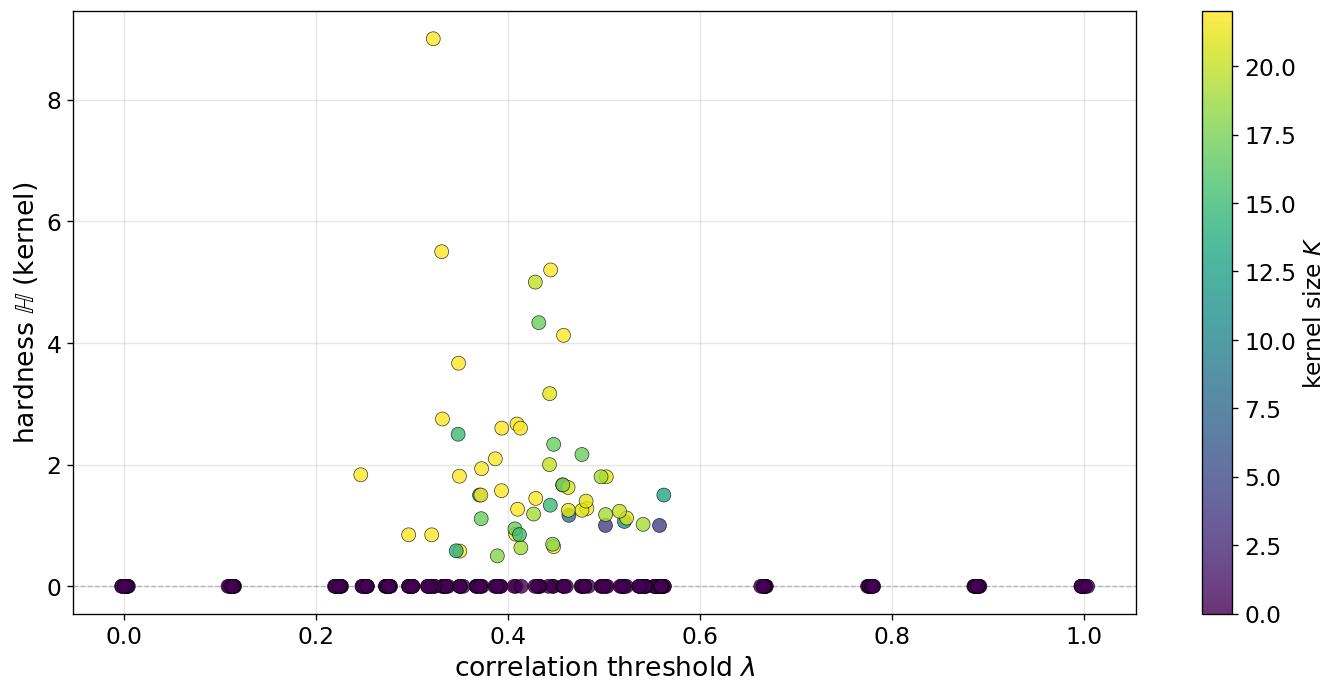

Total instances: 250
  K = 0: 193
  K > 0, h > 0: 57
  K > 0, h = 0/NaN: 0


In [11]:
# ══════════════════════════════════════════════════════════════════════════════
# Fig. 13 -- hardness vs threshold, all 250 instances, coloured by kernel size K
# K=0 instances get hardness=0 (plotted at y=0 strip at the bottom)
# ══════════════════════════════════════════════════════════════════════════════
df_ht = df_hardness.copy()
df_ht["kernel_size"] = df_ht.apply(
    lambda r: instance_info.get((r["threshold"], r["seed"]), {}).get("kernel_size", 0), axis=1)
# For K=0 instances, hardness is NaN or 0 — set to 0 for plotting
df_ht["h_plot"] = df_ht["hardness"].fillna(0).clip(lower=0)

fig, ax = plt.subplots(figsize=(12, 6))

# Small jitter on threshold so overlapping points are visible
rng_jit = np.random.default_rng(42)
jit = rng_jit.uniform(-0.004, 0.004, size=len(df_ht))

sc = ax.scatter(
    df_ht["threshold"].values + jit,
    df_ht["h_plot"].values,
    c=df_ht["kernel_size"].values,
    cmap="viridis",
    s=70, edgecolors="k", linewidths=0.4, alpha=0.8, zorder=3,
    vmin=0, vmax=df_ht["kernel_size"].max(),
)
cbar = plt.colorbar(sc, ax=ax)
cbar.set_label("kernel size $K$", fontsize=14)

# Mark K=0 region
ax.axhline(0, color="gray", linewidth=0.8, linestyle="--", alpha=0.5)

ax.set_xlabel("correlation threshold $\\lambda$", fontsize=16)
ax.set_ylabel(r"hardness $\mathbb{H}$ (kernel)", fontsize=16)
ax.grid(True, alpha=0.3)

plt.tight_layout()
if SAVE_FIGURES:
    plt.savefig("figures/final_hardness_vs_threshold_heatmap_N22.png", dpi=300, bbox_inches="tight")
plt.show()

# Summary
print(f"Total instances: {len(df_ht)}")
print(f"  K = 0: {(df_ht['kernel_size'] == 0).sum()}")
print(f"  K > 0, h > 0: {((df_ht['kernel_size'] > 0) & (df_ht['h_plot'] > 0)).sum()}")
print(f"  K > 0, h = 0/NaN: {((df_ht['kernel_size'] > 0) & (df_ht['h_plot'] == 0)).sum()}")


## 6. Fig. 14 — performance metrics vs hardness

Instances with non-trivial hardness: 114 ({'QAOA': 57, 'qReduMIS': 57})


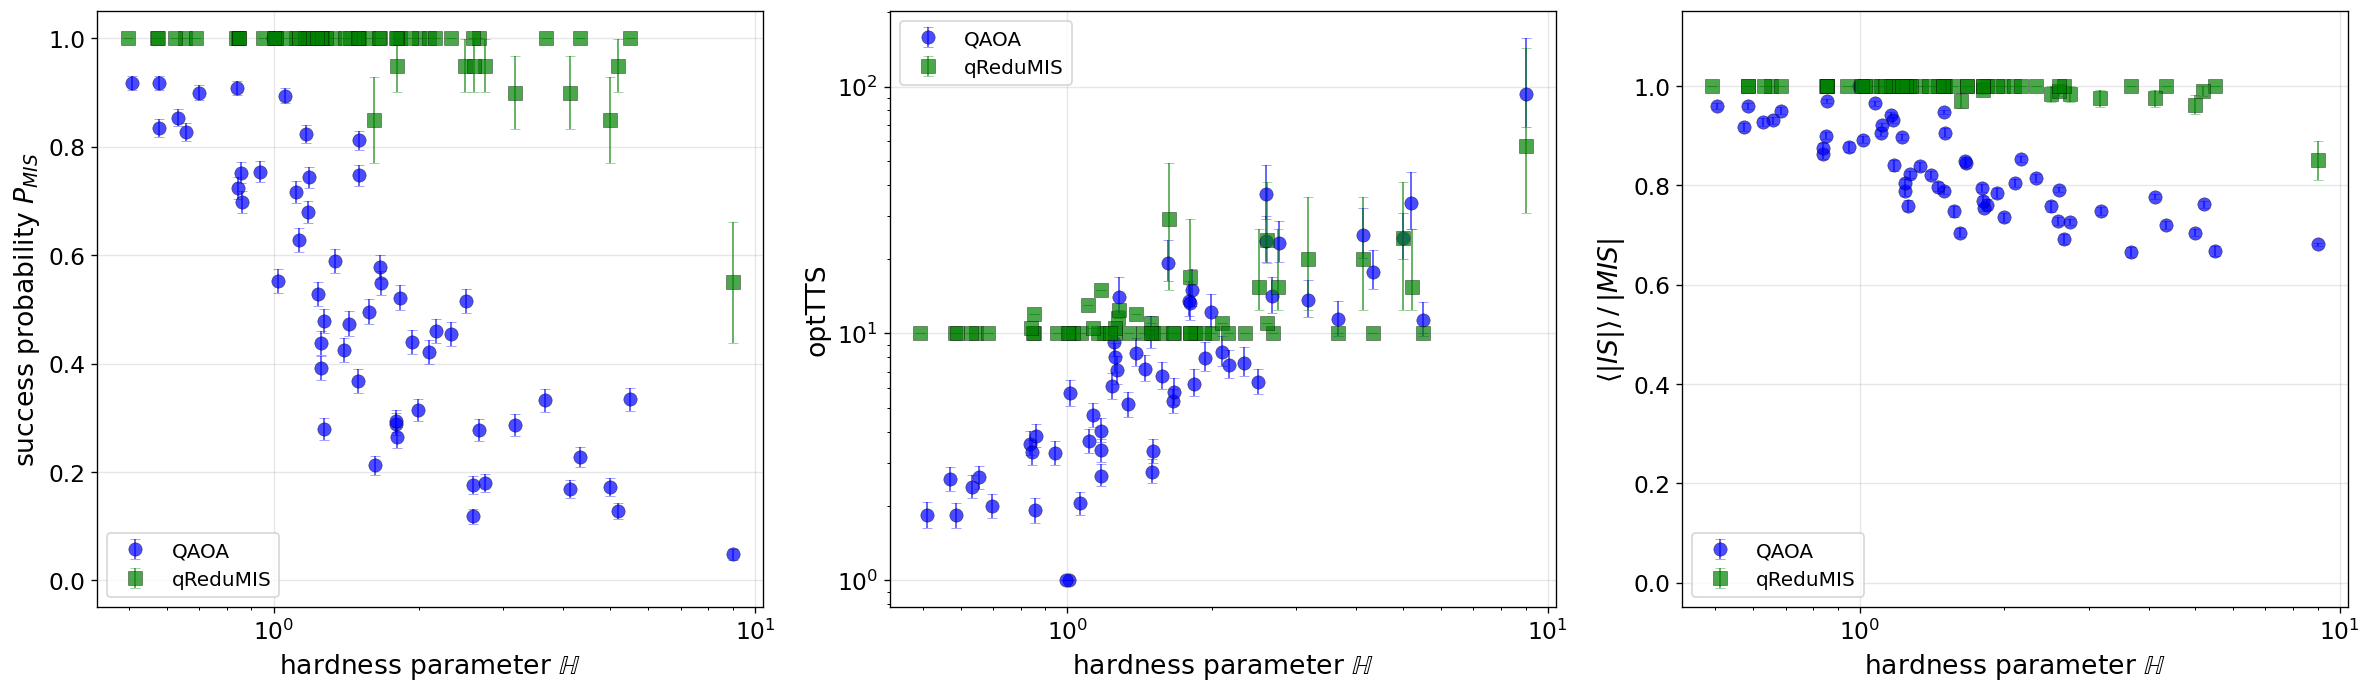

In [12]:
# Fig. 14 -- P_MIS, optTTS and <|IS|>/|MIS| vs hardness (instances with K > 0)
# Filter to instances with non-trivial hardness
df_hard = df_all[df_all["hardness"].notna() & (df_all["hardness"] > 0)].copy()
print(f"Instances with non-trivial hardness: {len(df_hard)} "
      f"({df_hard['method'].value_counts().to_dict()})")

if len(df_hard) == 0:
    print("No instances with non-trivial hardness — skipping hardness plots.")
else:
    fig, axes = plt.subplots(1, 3, figsize=(20, 6))
    rng_h = np.random.default_rng(42)

    # ── (a) Success Probability ────────────────────────────────────────
    ax = axes[0]
    for method in ["QAOA", "qReduMIS"]:
        sub = df_hard[df_hard["method"] == method]
        jit = rng_h.uniform(-0.01, 0.01, size=len(sub))
        yerr_inst = sub["p_success_std"].fillna(0).values
        ax.errorbar(sub["hardness"].values + jit, sub["p_success"].values,
                    yerr=yerr_inst, fmt=markers[method], color=colors[method],
                    alpha=0.7, markersize=8, capsize=3, capthick=1,
                    elinewidth=1, markeredgecolor="k", markeredgewidth=0.3,
                    zorder=2, label=method)
    ax.set_xlabel(r"hardness parameter $\mathbb{H}$", fontsize=16)
    ax.set_ylabel("success probability $P_{MIS}$", fontsize=16)
    ax.legend(fontsize=12, frameon=True)
    ax.set_ylim(-0.05, 1.05)
    ax.set_xscale("log")
    ax.grid(True, alpha=0.3)

    # ── (b) optTTS with bootstrap CI ──────────────────────────────────
    ax = axes[1]
    for method in ["QAOA", "qReduMIS"]:
        sub = df_hard[df_hard["method"] == method]
        valid = sub[np.isfinite(sub["opt_tts"])
                    & np.isfinite(sub["opt_tts_lo"]) & np.isfinite(sub["opt_tts_hi"])]
        jit = rng_h.uniform(-0.01, 0.01, size=len(valid))
        yerr_lo = (valid["opt_tts"] - valid["opt_tts_lo"]).clip(lower=0).values
        yerr_hi = (valid["opt_tts_hi"] - valid["opt_tts"]).clip(lower=0).values
        ax.errorbar(valid["hardness"].values + jit, valid["opt_tts"].values,
                    yerr=[yerr_lo, yerr_hi],
                    fmt=markers[method], color=colors[method],
                    alpha=0.7, markersize=8, capsize=3, capthick=1,
                    elinewidth=1, markeredgecolor="k", markeredgewidth=0.3,
                    zorder=2, label=method)
    ax.set_xlabel(r"hardness parameter $\mathbb{H}$", fontsize=16)
    ax.set_ylabel("optTTS", fontsize=16)
    ax.set_yscale("log")
    ax.set_xscale("log")
    ax.legend(fontsize=12, frameon=True)
    ax.grid(True, alpha=0.3)

    # ── (c) Weighted Energy ────────────────────────────────────────────
    ax = axes[2]
    for method in ["QAOA", "qReduMIS"]:
        sub = df_hard[df_hard["method"] == method]
        jit = rng_h.uniform(-0.01, 0.01, size=len(sub))
        yerr_inst = sub["weighted_ar_std"].fillna(0).values
        ax.errorbar(sub["hardness"].values + jit, sub["weighted_ar"].values,
                    yerr=yerr_inst, fmt=markers[method], color=colors[method],
                    alpha=0.7, markersize=8, capsize=3, capthick=1,
                    elinewidth=1, markeredgecolor="k", markeredgewidth=0.3,
                    zorder=2, label=method)
    ax.set_xlabel(r"hardness parameter $\mathbb{H}$", fontsize=16)
    ax.set_ylabel(r"$\langle |IS| \rangle \, / \, |MIS|$", fontsize=16)
    ax.set_ylim(-0.05, 1.15)
    ax.set_xscale("log")
    ax.legend(fontsize=12, frameon=True, loc="lower left")
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    if SAVE_FIGURES:
        plt.savefig("figures/final_metrics_vs_hardness_N22.png", dpi=300, bbox_inches="tight")
    plt.show()
